In [4]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
DATA_PATH = Path("Water Quality.csv")
OUTPUT_DIR = Path("aquainsight_task13_15_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [5]:
if not DATA_PATH.exists():
    found = list(Path.cwd().glob("*.csv"))
    if len(found) == 1:
        DATA_PATH = found[0]
    else:
        raise FileNotFoundError("Put Water Quality.csv beside this notebook or edit DATA_PATH.")

raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Raw shape:", raw.shape)
print("Media types:", raw["ActivityMediaName"].value_counts(dropna=False).head(10).to_dict())
display(raw.head())
print("\nMost common parameters:")
display(raw["CharacteristicName"].value_counts().head(35).to_frame("row_count"))
print("\nUnits by parameter:")
display(raw.groupby("CharacteristicName")["ResultUnit"].agg(lambda s: ", ".join(sorted(set(s.dropna().astype(str))))).to_frame("units").head(50))

Raw shape: (229916, 40)
Media types: {'Surface Water': 229916}


,DatasetName,MonitoringLocationID,MonitoringLocationName,MonitoringLocationLatitude,MonitoringLocationLongitude,MonitoringLocationHorizontalCoordinateReferenceSystem,MonitoringLocationHorizontalAccuracyMeasure,MonitoringLocationHorizontalAccuracyUnit,MonitoringLocationVerticalMeasure,MonitoringLocationVerticalUnit,...,ResultStatusID,ResultComment,ResultAnalyticalMethodID,ResultAnalyticalMethodContext,ResultAnalyticalMethodName,AnalysisStartDate,AnalysisStartTime,AnalysisStartTimeZone,LaboratoryName,LaboratorySampleID
0,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,110688,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
1,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,2011,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
2,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,20110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
3,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,17209,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
4,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,10110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN



Most common parameters:


,row_count
CharacteristicName,
Specific conductance,8963
pH,8946
"Total Nitrogen, mixed forms",7333
Magnesium,7312
Calcium,7307
Sodium,7300
Organic carbon,7272
Chloride,7250
Sulfate,7240



Units by parameter:


,units
CharacteristicName,
"Alkalinity, total",mg/L
Aluminum,"mg/L, ug/L"
Ammonia,mg/L
Antimony,ug/L
Apparent color,TCU
Arsenic,"mg/L, ug/L"
Barium,"mg/L, ug/L"
Beryllium,ug/L
Bismuth,ug/L


In [6]:
# Canonical parameters are kept only where a clear unit conversion is possible.
# Metals are converted to ug/L; nitrate and fluoride remain mg/L.
PARAMETER_MAP = {
    "pH": "pH",
    "Dissolved oxygen (DO)": "DO_mg_L",
    "Dissolved oxygen saturation": "DO_saturation_pct",
    "Turbidity": "Turbidity_NTU",
    "Nitrate": "Nitrate_mg_L",
    "Fluoride": "Fluoride_mg_L",
    "Arsenic": "Arsenic_ug_L",
    "Lead": "Lead_ug_L",
    "Cadmium": "Cadmium_ug_L",
    "Selenium": "Selenium_ug_L",
    "Uranium": "Uranium_ug_L",
    "Manganese": "Manganese_ug_L",
    "Temperature, water": "Temperature_C",
    "Fecal Coliform": "Fecal_Coliform_per_100mL",
    "Total Phosphorus, mixed forms": "Total_Phosphorus_mg_L"
}
d = raw[raw["CharacteristicName"].isin(PARAMETER_MAP)].copy()
d["ResultValue"] = pd.to_numeric(d["ResultValue"], errors="coerce")
d = d.dropna(subset=["ResultValue"])
d["Canonical"] = d["CharacteristicName"].map(PARAMETER_MAP)
d["UnitClean"] = d["ResultUnit"].astype(str).str.strip()

# Convert supported units. Unsupported unit variants become missing rather than silently mixed.
def convert_row(r):
    v, u, p = r["ResultValue"], r["UnitClean"], r["Canonical"]
    if p == "pH":
        return v if u in ("nan", "", "None") else v
    if p in ("DO_mg_L", "Nitrate_mg_L", "Fluoride_mg_L", "Total_Phosphorus_mg_L"):
        return v if u.lower() in ("mg/l", "mg/l as n", "mg/l as p") else np.nan
    if p == "DO_saturation_pct":
        return v if "%" in u or "percent" in u.lower() else np.nan
    if p == "Turbidity_NTU":
        return v if u.upper() == "NTU" else np.nan
    if p == "Temperature_C":
        return v if u.lower() in ("deg c", "°c", "degree celsius") else np.nan
    if p == "Fecal_Coliform_per_100mL":
        return v if "#/100mL" in u.replace(" ", "") else np.nan
    if p.endswith("_ug_L"):
        if u.lower() in ("ug/l", "µg/l"):
            return v
        if u.lower() == "mg/l":
            return v * 1000.0
        return np.nan
    return np.nan

d["ValueStandard"] = d.apply(convert_row, axis=1)
d = d.dropna(subset=["ValueStandard"])
sample_keys = [c for c in ["MonitoringLocationID", "ActivityStartDate"] if c in d.columns]
if not sample_keys:
    raise ValueError("Expected MonitoringLocationID and/or ActivityStartDate to identify samples.")
if "ActivityStartDate" in d.columns:
    d["ActivityStartDate"] = pd.to_datetime(d["ActivityStartDate"], errors="coerce")
    d = d.dropna(subset=["ActivityStartDate"])

samples = d.pivot_table(index=sample_keys, columns="Canonical", values="ValueStandard", aggfunc="mean").reset_index()
samples.columns.name = None
print("Sample-level table:", samples.shape)
display(samples.head())
print("Available canonical parameters:", [c for c in samples.columns if c not in sample_keys])

Sample-level table: (7282, 17)


,MonitoringLocationID,ActivityStartDate,Arsenic_ug_L,Cadmium_ug_L,DO_mg_L,DO_saturation_pct,Fecal_Coliform_per_100mL,Fluoride_mg_L,Lead_ug_L,Manganese_ug_L,Nitrate_mg_L,Selenium_ug_L,Temperature_C,Total_Phosphorus_mg_L,Turbidity_NTU,Uranium_ug_L,pH
0,NB01BR0006,2000-09-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.032,NaN,NaN,NaN
1,NB01BR0006,2000-10-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.038,NaN,NaN,NaN
2,NB01BR0006,2000-11-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011,NaN,NaN,NaN
3,NB01BR0006,2001-04-26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.024,NaN,NaN,4.9
4,NB01BR0006,2001-05-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.015,NaN,NaN,5.1


Available canonical parameters: ['Arsenic_ug_L', 'Cadmium_ug_L', 'DO_mg_L', 'DO_saturation_pct', 'Fecal_Coliform_per_100mL', 'Fluoride_mg_L', 'Lead_ug_L', 'Manganese_ug_L', 'Nitrate_mg_L', 'Selenium_ug_L', 'Temperature_C', 'Total_Phosphorus_mg_L', 'Turbidity_NTU', 'Uranium_ug_L', 'pH']


In [7]:
# NSF classic parameter weights (Brown et al. convention).
# Parameters absent from the dataset or not unit-compatible are omitted and remaining weights renormalized.
NSF_WEIGHTS = {
    "DO_saturation_pct": 0.17,
    "Fecal_Coliform_per_100mL": 0.16,
    "pH": 0.11,
    "Nitrate_mg_L": 0.10,
    "Temperature_C": 0.10,
    "Turbidity_NTU": 0.08
}
available_nsf = [p for p in NSF_WEIGHTS if p in samples.columns]
print("Available NSF-related inputs:", available_nsf)
print("Unavailable classic NSF inputs include BOD and Total Solids; this is not the full NSF method.")

def nsf_proxy_subindex(param, s):
    # Transparent, editable proxy scoring rules (0–100); NOT original NSF rating curves.
    x = pd.to_numeric(s, errors="coerce")
    if param == "pH":
        # Score 100 within 6.5–8.5; linear decline outside.
        return (100 - np.where(x < 6.5, (6.5-x)*25,
                    np.where(x > 8.5, (x-8.5)*25, 0))).clip(0,100)
    if param == "DO_saturation_pct":
        return (x / 100 * 100).clip(0,100)
    if param == "Turbidity_NTU":
        return (100 - (x/5)*100).clip(0,100)
    if param == "Nitrate_mg_L":
        return (100 - (x/10)*100).clip(0,100)
    if param == "Fecal_Coliform_per_100mL":
        return (100 - np.log10(1+x)*25).clip(0,100)
    if param == "Temperature_C":
        # Illustrative relative deviation from 20 C; actual NSF curve uses temperature change.
        return (100 - np.abs(x-20)*4).clip(0,100)
    return pd.Series(np.nan, index=s.index)

nsf_sub = pd.DataFrame(index=samples.index)
for p in available_nsf:
    nsf_sub[p] = nsf_proxy_subindex(p, samples[p])
w = pd.Series({p:NSF_WEIGHTS[p] for p in available_nsf}, dtype=float)
nsf_score = nsf_sub.mul(w, axis=1).sum(axis=1, min_count=1) / nsf_sub.notna().mul(w, axis=1).sum(axis=1).replace(0,np.nan)
samples["NSF_weighted_available_proxy"] = nsf_score
print("NSF proxy computed for samples:", int(nsf_score.notna().sum()))

Available NSF-related inputs: ['DO_saturation_pct', 'Fecal_Coliform_per_100mL', 'pH', 'Nitrate_mg_L', 'Temperature_C', 'Turbidity_NTU']
Unavailable classic NSF inputs include BOD and Total Solids; this is not the full NSF method.
NSF proxy computed for samples: 7282


In [8]:
# CCME objective table is intentionally editable. These are illustrative screening values,
# NOT a claim that one universal surface-water standard exists.
# direction='max': exceedance if result > objective; 'min': result < objective;
# direction='range': exceedance outside [lower, upper].
CCME_OBJECTIVES = {
    "pH": {"direction":"range", "lower":6.5, "upper":8.5},
    "DO_mg_L": {"direction":"min", "value":5.0},
    "Turbidity_NTU": {"direction":"max", "value":5.0},
    "Nitrate_mg_L": {"direction":"max", "value":10.0}
}
print("EDIT these objectives to match the designated water use and applicable local standards.")

EDIT these objectives to match the designated water use and applicable local standards.


In [9]:

def ccme_wqi_site(group, objectives):
    # CCME requires repeated tests across a defined site/assessment period.
    # This calculates one site-level score from all available tests in the group.
    tests = []
    for param, obj in objectives.items():
        if param not in group.columns:
            continue
        values = pd.to_numeric(group[param], errors="coerce").dropna()
        for x in values:
            x = float(x)
            if obj["direction"] == "max":
                failed = x > obj["value"]
                excursion = (x/obj["value"])-1 if failed and obj["value"] != 0 else 0
            elif obj["direction"] == "min":
                failed = x < obj["value"]
                excursion = (obj["value"]/x)-1 if failed and x > 0 else (1e6 if failed else 0)
            else:
                failed = x < obj["lower"] or x > obj["upper"]
                if x < obj["lower"]:
                    excursion = obj["lower"]/x - 1 if x > 0 else 1e6
                elif x > obj["upper"]:
                    excursion = x/obj["upper"] - 1
                else:
                    excursion = 0
            tests.append((param, failed, max(0.0, excursion)))
    if len(tests) < 2:
        return np.nan
    n_vars = len(set(t[0] for t in tests))
    failed_vars = len(set(t[0] for t in tests if t[1]))
    n_tests = len(tests)
    failed_tests = sum(t[1] for t in tests)
    F1 = 100 * failed_vars / n_vars
    F2 = 100 * failed_tests / n_tests
    failed_excursions = [t[2] for t in tests if t[1]]
    nse = float(np.mean(failed_excursions)) if failed_excursions else 0.0
    F3 = nse / (0.01*nse + 0.01)
    return 100 - (np.sqrt(F1**2 + F2**2 + F3**2) / 1.732)

if "MonitoringLocationID" in samples.columns:
    site_ccme = samples.groupby("MonitoringLocationID", dropna=True).apply(
        lambda g: ccme_wqi_site(g, CCME_OBJECTIVES), include_groups=False
    )
    samples["CCME_illustrative_objective_score"] = samples["MonitoringLocationID"].map(site_ccme)
else:
    samples["CCME_illustrative_objective_score"] = np.nan

print("Site-level CCME-style scores computed:", int(site_ccme.notna().sum()) if "MonitoringLocationID" in samples.columns else 0)
print("Each site score uses repeated available tests across dates; objectives remain illustrative/editable.")


Site-level CCME-style scores computed: 58
Each site score uses repeated available tests across dates; objectives remain illustrative/editable.


In [10]:
# WHO guideline reference table: drinking-water values only, with standardized units.
# Do not apply these drinking-water guideline values as surface-water ecosystem objectives.
# Values below are a selected subset; verify the current WHO edition and national standard before formal use.
WHO_GUIDELINES = {
    "Arsenic_ug_L": {"value":10.0, "unit":"ug/L", "basis":"WHO drinking-water guideline value"},
    "Lead_ug_L": {"value":10.0, "unit":"ug/L", "basis":"WHO provisional drinking-water guideline value"},
    "Fluoride_mg_L": {"value":1.5, "unit":"mg/L", "basis":"WHO drinking-water guideline value"},
    "Nitrate_mg_L": {"value":50.0, "unit":"mg/L", "basis":"as nitrate; confirm reporting basis"},
    "Cadmium_ug_L": {"value":3.0, "unit":"ug/L", "basis":"WHO drinking-water guideline value"},
    "Selenium_ug_L": {"value":40.0, "unit":"ug/L", "basis":"WHO drinking-water guideline value"},
    "Uranium_ug_L": {"value":30.0, "unit":"ug/L", "basis":"WHO drinking-water guideline value"},
    "Manganese_ug_L": {"value":80.0, "unit":"ug/L", "basis":"provisional guideline value; check edition"}
}
who_results = []
for param, spec in WHO_GUIDELINES.items():
    if param not in samples.columns:
        continue
    valid_values = samples[param].dropna()
    if len(valid_values) == 0:
        continue
    exceed = valid_values > spec["value"]
    who_results.append({
        "Parameter":param, "Unit":spec["unit"], "Reference value":spec["value"],
        "Observed tests":len(valid_values), "Exceedances":int(exceed.sum()),
        "Exceedance percent":100*exceed.mean(), "Basis":spec["basis"]
    })
who_table = pd.DataFrame(who_results)
display(who_table)
who_table.to_csv(OUTPUT_DIR/"task13_who_guideline_exceedance_summary.csv",index=False)

,Parameter,Unit,Reference value,Observed tests,Exceedances,Exceedance percent,Basis
0,Arsenic_ug_L,ug/L,10.0,5929,0,0.000000,WHO drinking-water guideline value
1,Lead_ug_L,ug/L,10.0,6012,12,0.199601,WHO provisional drinking-water guideline value
2,Fluoride_mg_L,mg/L,1.5,995,0,0.000000,WHO drinking-water guideline value
3,Nitrate_mg_L,mg/L,50.0,2114,0,0.000000,as nitrate; confirm reporting basis
4,Cadmium_ug_L,ug/L,3.0,1990,2,0.100503,WHO drinking-water guideline value
5,Selenium_ug_L,ug/L,40.0,3991,0,0.000000,WHO drinking-water guideline value
6,Uranium_ug_L,ug/L,30.0,3416,0,0.000000,WHO drinking-water guideline value
7,Manganese_ug_L,ug/L,80.0,6920,1139,16.459538,provisional guideline value; check edition


,count,mean,std,min,25%,50%,75%,max
NSF_weighted_available_proxy,7282.0,74.696326,13.611964,31.842105,64.750000,74.696898,84.994144,100.0
CCME_illustrative_objective_score,7282.0,49.337863,12.020790,37.541562,39.874646,46.513811,54.110802,100.0


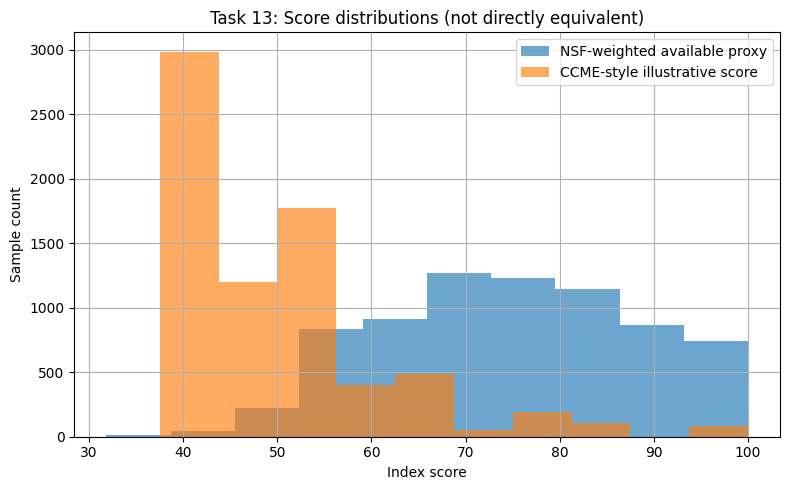

In [11]:
# Compare the two numerical index-style outputs on their common valid samples.
comparison = samples[["NSF_weighted_available_proxy","CCME_illustrative_objective_score"]].describe().T
display(comparison)
samples[[*sample_keys,"NSF_weighted_available_proxy","CCME_illustrative_objective_score"]].to_csv(
    OUTPUT_DIR/"task13_sample_level_index_comparison.csv",index=False
)

plt.figure(figsize=(8,5))
samples["NSF_weighted_available_proxy"].dropna().hist(alpha=.65,label="NSF-weighted available proxy")
samples["CCME_illustrative_objective_score"].dropna().hist(alpha=.65,label="CCME-style illustrative score")
plt.xlabel("Index score"); plt.ylabel("Sample count"); plt.title("Task 13: Score distributions (not directly equivalent)")
plt.legend(); plt.tight_layout(); plt.show()